# 03. Связь точных оценок с категориями


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Тот же анализ связей, но только для оценок с точностью не ниже 0.8.

| | |
|---|---|
| **Данные** | `data/scores_accuracy.csv` |
| **Фильтр** | `rel_* >= 0.8` |
| **Цель** | Понять, какие категории сильнее связаны с уже надёжными оценками |


In [2]:
library(tidyr)
library(dplyr)
library(ggplot2)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



In [3]:
estimates <- c("output", "related", "frequency", "yield", "volume", "defect")
cat_columns <- c("type", "year", "series", "plant", "method", "certified")


# 1. Введение

Прогнозные оценки имеют разную точность. Здесь оставляем только те, которым можно доверять (коэффициент точности ≥ 0.8), и смотрим их связь с характеристиками изделия.

# 2. Данные


In [4]:
scores <- read.csv("data/scores_accuracy.csv")

filter_reliability <- function(estimation, rel_coef) {
  scores %>%
    filter(.data[[paste0("rel_", estimation)]] >= rel_coef) %>%
    dplyr::select(type, series, year, plant, method, certified, .data[[estimation]]) %>%
    mutate(
      plant = ifelse(is.na(plant), "Неизвестно", plant),
      method = ifelse(is.na(method), "Неизвестно", method)
    )
}

take_n <- function(df, n = 5000) {
  if (nrow(df) <= n) df else df[sample(nrow(df), n), ]
}

output_sc <- filter_reliability("output", 0.8)
related_sc <- filter_reliability("related", 0.8)
yield_sc <- filter_reliability("yield", 0.8)
volume_sc <- filter_reliability("volume", 0.8)
frequency_sc <- filter_reliability("frequency", 0.8)
defect_sc <- filter_reliability("defect", 0.8)


Use of .data in tidyselect expressions was deprecated in tidyselect 1.2.0.
ℹ Please use `all_of(var)` (or `any_of(var)`) instead of `.data[[var]]`


Размеры выборок после фильтра по точности:




|estimate  |    n|
|:---------|----:|
|output    | 1392|
|related   | 1077|
|frequency |  938|
|yield     | 1025|
|volume    |  952|
|defect    |  188|


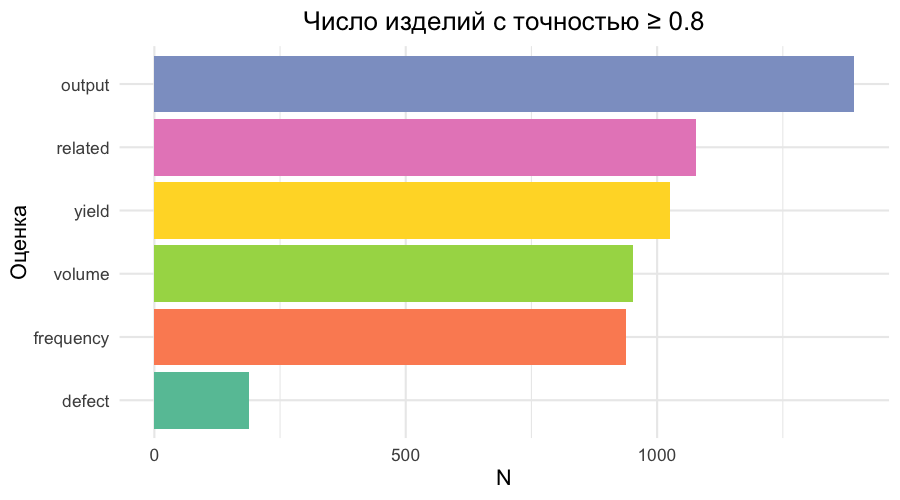

In [5]:
n_tbl <- data.frame(
  estimate = estimates,
  n = c(
    nrow(output_sc), nrow(related_sc), nrow(frequency_sc),
    nrow(yield_sc), nrow(volume_sc), nrow(defect_sc)
  )
)
knitr::kable(n_tbl)
ggplot(n_tbl, aes(x = reorder(estimate, n), y = n, fill = estimate)) +
  geom_col() +
  coord_flip() +
  scale_fill_brewer(palette = "Set2", guide = "none") +
  labs(title = "Число изделий с точностью ≥ 0.8", x = "Оценка", y = "N") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# 3. Связь числа и категории

1. Нормальность — Шапиро–Уилк.  
2. Нормальное → ANOVA, иначе → Краскел–Уоллис.


In [6]:
shapiro_sample <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) > 5000) x <- sample(x, 5000)
  x
}

сategory_dependency <- function(dataset, var_1, var_2) {
  x <- shapiro_sample(dataset[[var_1]])
  if (shapiro.test(x)$p.value < 0.05) {
    kt <- kruskal.test(dataset[[var_1]] ~ dataset[[var_2]], data = dataset)
    return(c(var_2, as.numeric(kt$statistic), as.numeric(kt$p.value)))
  }
  result <- aov(dataset[[var_1]] ~ dataset[[var_2]], data = dataset)
  c(var_2, summary.aov(result)[[1]][["F value"]][1], summary.aov(result)[[1]][["Pr(>F)"]][1])
}

category_dependency_df <- function(dataset, vector, col) {
  as.data.frame(t(sapply(vector, function(var) сategory_dependency(dataset, col, var)))) %>%
    mutate(column_to = col) %>%
    dplyr::select(V1, column_to, V2, V3) %>%
    rename(column_from = V1, statistic = V2, p_value = V3) %>%
    `rownames<-`(NULL) %>%
    mutate(
      statistic = as.numeric(statistic),
      p_value = as.numeric(p_value),
      is_significance = p_value < 0.05
    ) %>%
    arrange(p_value)
}


# 4. Оценки и категории

Оценки: производительность, сопутствующий выпуск, выход годного, частота выпуска, объём партии, доля брака.  
Категории: тип, год выпуска, серия, площадка, метод изготовления, сертификация.




|column_from |column_to | statistic| p_value|is_significance |
|:-----------|:---------|---------:|-------:|:---------------|
|series      |output    |    5.4612|  0.0000|TRUE            |
|type        |output    |    6.8917|  0.0088|TRUE            |
|plant       |output    |    1.8206|  0.1058|FALSE           |
|year        |output    |    1.5798|  0.2090|FALSE           |
|certified   |output    |    0.2050|  0.6508|FALSE           |
|method      |output    |    0.1484|  0.8621|FALSE           |
|year        |related   |   30.8967|  0.0000|TRUE            |
|series      |related   |    1.8040|  0.0297|TRUE            |
|method      |related   |    1.6424|  0.1940|FALSE           |
|type        |related   |    1.2504|  0.2637|FALSE           |
|certified   |related   |    0.4073|  0.5235|FALSE           |
|plant       |related   |    0.2907|  0.9183|FALSE           |
|method      |yield     |   85.0294|  0.0000|TRUE            |
|year        |yield     |   38.4708|  0.0001|TRUE    

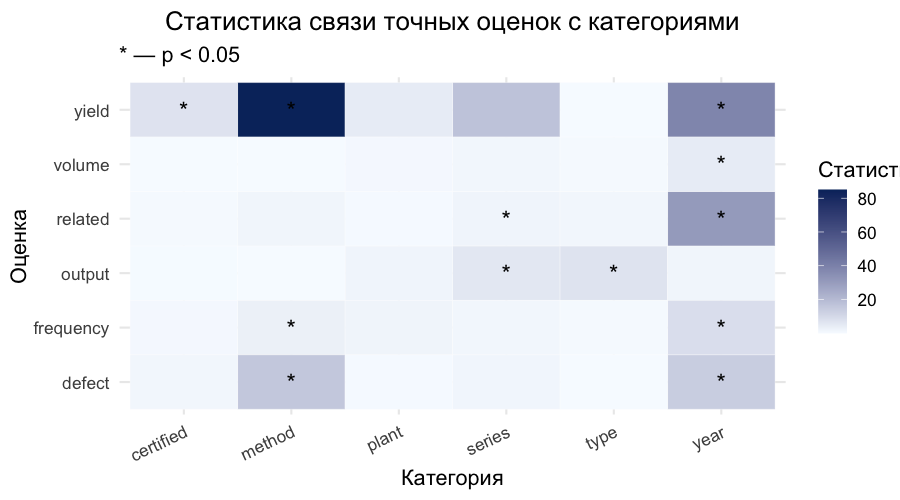

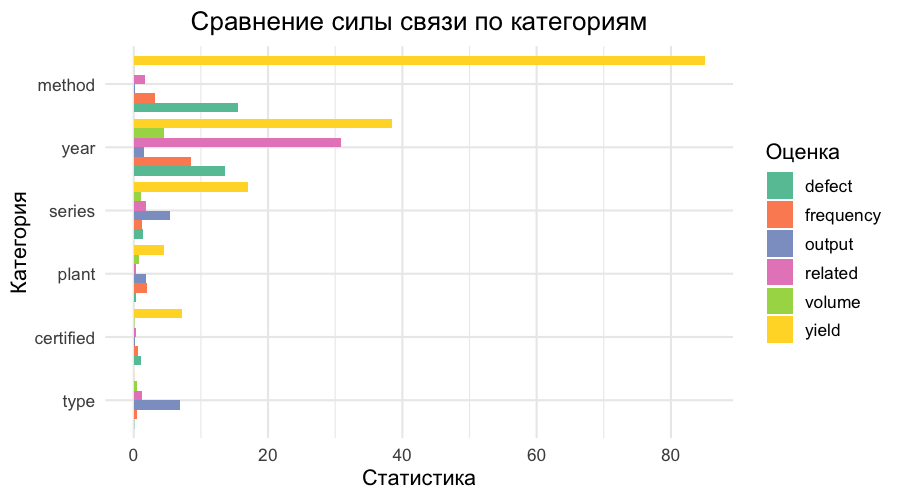

In [7]:
dep_all <- bind_rows(
  category_dependency_df(take_n(output_sc), cat_columns, "output"),
  category_dependency_df(related_sc, cat_columns, "related"),
  category_dependency_df(take_n(yield_sc), cat_columns, "yield"),
  category_dependency_df(take_n(volume_sc), cat_columns, "volume"),
  category_dependency_df(frequency_sc, cat_columns, "frequency"),
  category_dependency_df(defect_sc, cat_columns, "defect")
)
knitr::kable(dep_all, digits = 4)
ggplot(dep_all, aes(column_from, column_to, fill = statistic)) +
  geom_tile(color = "white") +
  geom_text(aes(label = ifelse(is_significance, "*", "")), size = 5) +
  scale_fill_gradient(low = "#f7fbff", high = "#08306b") +
  labs(
    title = "Статистика связи точных оценок с категориями",
    subtitle = "* — p < 0.05",
    x = "Категория", y = "Оценка", fill = "Статистика"
  ) +
  theme_minimal(base_size = 13) +
  theme(axis.text.x = element_text(angle = 25, hjust = 1), plot.title = element_text(hjust = 0.5))
ggplot(dep_all, aes(x = reorder(column_from, statistic), y = statistic, fill = column_to)) +
  geom_col(position = "dodge") +
  coord_flip() +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "Сравнение силы связи по категориям", x = "Категория", y = "Статистика", fill = "Оценка") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


Распределения ненормальные, почти все связи значимы. Чаще всего оценку определяет серия; для частоты выпуска сильнее год выпуска. Площадка тоже заметна. Сертификация, метод и тип влияют слабее.

# 5. Заключение

Даже среди точных оценок связь с категориями сохраняется. Серия и площадка — основные источники различий.
